In [31]:
from sklearn.linear_model import LassoCV
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns

In [32]:
insurance_data = pd.read_csv("../Data-Files/insurance.csv")


X = insurance_data.drop(columns=["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"female": 1,"male": 0})
X["smoker"] = X["smoker"].map({"yes": 1 , "no": 0})
X["age_smoker"] = X["age"] * X["smoker"]
X["age_bmi"] = X["age"] * X["bmi"]
X["smoker_bmi"] =  X["smoker"]  * X["bmi"]
X["age_smoker_bmi"] = X["age"] * X["smoker"] * X["bmi"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# model = LinearRegression()
# model.fit(X_train, y_train)

# y_pred = model.predict(X_test)
# r2 = r2_score(y_test, y_pred )
# r2

In [33]:
alphas = [0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 3, 5, 7, 9, 15, 25, 40, 50, 60, 75, 85, 100]
mse_val = {}
mses = []
final = {}

for alpha in alphas:
    lasso_model = Lasso(alpha)
    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)    
    mses.append(mse)
    mse_val[alpha] = mse

mini = next(iter(mse_val.values()))
for key in mse_val:
    if mse_val[key] < mini:
        final = {key: mini}
print(final)

{40: 20773282.164532725}


c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.279e+10, tolerance: 1.544e+07
  model = cd_fast.enet_coordinate_descent(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.274e+10, tolerance: 1.544e+07
  model = cd_fast.enet_coordinate_descent(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.269e+10, toler

<Axes: >

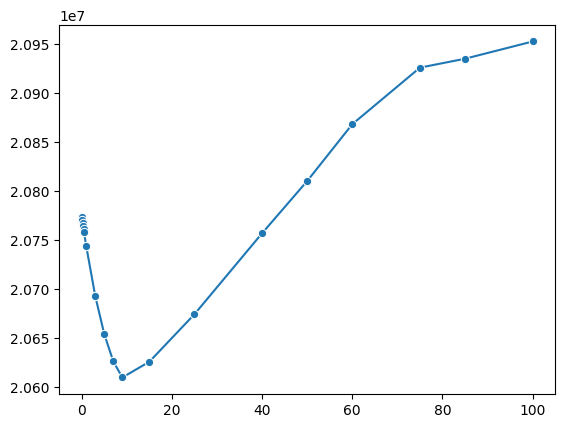

In [34]:
sns.lineplot(
    x=alphas,
    y=mses,
    marker='o'
)

In [35]:
from operator import itemgetter
val = min(mse_val.items(), key=itemgetter(1))
print(val)


(9, 20609787.247293144)


In [ ]:
alphas = [0.001, 0,  0.1, 0.2, 0.3, 0.4, 0.5, 1, 3, 5, 7, 9, 15, 25, 40, 50, 60, 75, 85, 100]
lasso_cv_model = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=10000,
    random_state=42
)

lasso_cv_model.fit(X_train, y_train)
print("Best value", lasso_cv_model.alpha_)

Best value 0.0


c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.014e+10, tolerance: 1.242e+07
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\line

In [37]:
y_pred = lasso_cv_model.predict(X_test)
mze = mean_squared_error(y_test, y_pred)
print(mze)

20756885.69172513


In [39]:
r2 = r2_score(y_test, y_pred)
r2

0.8662991607578769